In [1]:
import os
import time
import pandas as pd
import tarfile
import pickle
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import optuna
from tqdm import tqdm

optuna.logging.set_verbosity(optuna.logging.WARNING)

In [ ]:
TAR_PATH = "data/cifar-100-python.tar.gz"
CKPT_DIR = "checkpoints"
RESULTS_DIR = "results"
SEED = 42
NUM_CLASSES = 100
DUMMY_ACC = 100.0 / NUM_CLASSES        

EPOCHS = 100   
PATIENCE = 10

# Pre-Tuned CNN parameters
BASELINE = dict(lr=1e-3, weight_decay=1e-4, dropout_rate=0.3, batch_size=64)
# Logistic Regression parameters (for comparison)
LOGREG = dict(lr=1e-2, weight_decay=1e-4, batch_size=64)

N_TRIALS = 50
N_EPOCHS = 20         
BATCH_SIZES = [32, 64, 128]
EVAL_BATCH_SIZE = 1024

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = device.type == "cuda"                         
ACT_DTYPE = torch.float16 if USE_AMP else torch.float32 

MEAN = torch.tensor((0.5071, 0.4867, 0.4408), device=device).view(1, 3, 1, 1)
STD = torch.tensor((0.2675, 0.2565, 0.2761), device=device).view(1, 3, 1, 1)

torch.backends.cudnn.benchmark = True
torch.manual_seed(SEED)
np.random.seed(SEED)
os.makedirs(CKPT_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)
print(f"Using device: {device} | AMP: {USE_AMP} | quick test: {QUICK_TEST}")

Using device: cuda | AMP: True | quick test: False


## GPU data utilities

In [3]:
def normalize(x_u8):
    """uint8 (B, 3, H, W) -> normalized float32, channels_last."""
    x = (x_u8.float().div_(255) - MEAN) / STD
    return x.contiguous(memory_format=torch.channels_last)


def augment_batch(x_u8, padding=4):
    """RandomCrop(32, padding=4) + RandomHorizontalFlip, independently per sample, on the GPU.
    Pads with zeros *before* normalization, exactly like the torchvision pipeline."""
    B, C, H, W = x_u8.shape
    dev = x_u8.device
    x = F.pad(x_u8, (padding,) * 4)
    i = torch.randint(0, 2 * padding + 1, (B,), device=dev)
    j = torch.randint(0, 2 * padding + 1, (B,), device=dev)
    rows = (i[:, None] + torch.arange(H, device=dev))[:, None, :, None]    # (B, 1, H, 1)
    cols = (j[:, None] + torch.arange(W, device=dev))[:, None, None, :]    # (B, 1, 1, W)
    b = torch.arange(B, device=dev)[:, None, None, None]
    c = torch.arange(C, device=dev)[None, :, None, None]
    x = x[b, c, rows, cols]                                                # (B, C, H, W)
    flip = torch.rand(B, device=dev) < 0.5
    return torch.where(flip[:, None, None, None], x.flip(3), x)


def make_epoch_tensor(X_u8, perm=None, augment=False, chunk=4096):
    """Normalized (optionally augmented) copy of X_u8, in `perm` order, as ACT_DTYPE channels_last.
    Built in chunks so the temporary float32 buffers stay small. One call per epoch replaces thousands
    of tiny per-batch augmentation kernels."""
    n = X_u8.size(0)
    out = torch.empty(X_u8.shape, dtype=ACT_DTYPE, device=X_u8.device, memory_format=torch.channels_last)
    for s in range(0, n, chunk):
        xb = X_u8[s : s + chunk] if perm is None else X_u8[perm[s : s + chunk]]
        if augment:
            xb = augment_batch(xb)
        out[s : s + chunk] = normalize(xb)
    return out

## Data: one pass over the tar, everything onto the GPU

In [4]:
def load_cifar100(tar_path):
    """Read train / test / meta from the tar in ONE pass. Returns uint8 arrays shaped (N, 3, 32, 32)."""
    found = {}
    with tarfile.open(tar_path, "r:gz") as tar:
        for member in tar:
            name = os.path.basename(member.name)
            if member.isfile() and name in ("train", "test", "meta"):
                found[name] = pickle.load(tar.extractfile(member), encoding="bytes")
                if len(found) == 3:
                    break
    missing = {"train", "test", "meta"} - found.keys()
    if missing:
        raise FileNotFoundError(f"{tar_path} is missing: {sorted(missing)}")
    X_tr = found["train"][b"data"].reshape(-1, 3, 32, 32)
    X_te = found["test"][b"data"].reshape(-1, 3, 32, 32)
    y_tr = np.asarray(found["train"][b"fine_labels"])
    y_te = np.asarray(found["test"][b"fine_labels"])
    names = [n.decode("utf-8") for n in found["meta"][b"fine_label_names"]]
    return X_tr, y_tr, X_te, y_te, names


X_full, y_full, X_test_np, y_test_np, CLASS_NAMES = load_cifar100(TAR_PATH)

# Stratified 80/20 train/val split (same indices as before: random_state=42)
train_idx, val_idx = train_test_split(
    np.arange(len(y_full)), test_size=0.2, stratify=y_full, random_state=SEED
)


def to_gpu(X_np, y_np):
    return torch.from_numpy(np.ascontiguousarray(X_np)).to(device), torch.from_numpy(y_np).long().to(device)


X_train, y_train = to_gpu(X_full[train_idx], y_full[train_idx])   # uint8, augmented fresh every epoch
X_val_u8, y_val = to_gpu(X_full[val_idx], y_full[val_idx])
X_test_u8, y_test = to_gpu(X_test_np, y_test_np)

# Val / test never change: normalize once and keep them as ready-to-use model inputs
X_val = make_epoch_tensor(X_val_u8)
X_test = make_epoch_tensor(X_test_u8)

print(f"train {tuple(X_train.shape)} | val {tuple(X_val.shape)} | test {tuple(X_test.shape)} | {len(CLASS_NAMES)} classes")

train (40000, 3, 32, 32) | val (10000, 3, 32, 32) | test (10000, 3, 32, 32) | 100 classes


## Models, training loop, evaluation

In [5]:
class Simple2DCNN(nn.Module):
    def __init__(self, dropout_rate=0.3, num_classes=100):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 64, 3, padding=1), nn.BatchNorm2d(64), nn.GELU(), nn.MaxPool2d(2, 2),
            nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.GELU(), nn.MaxPool2d(2, 2),
            nn.Conv2d(128, 256, 3, padding=1), nn.BatchNorm2d(256), nn.GELU(), nn.MaxPool2d(2, 2),
        )
        self.classifier = nn.Sequential(
            nn.Dropout(dropout_rate), nn.Linear(256 * 4 * 4, 512), nn.GELU(),
            nn.Dropout(dropout_rate), nn.Linear(512, num_classes),
        )

    def forward(self, x):
        return self.classifier(torch.flatten(self.features(x), 1))


class LogisticRegressionBaseline(nn.Module):
    def __init__(self, num_classes=100):
        super().__init__()
        self.linear = nn.Linear(3 * 32 * 32, num_classes)    # flatten the image straight to class logits

    def forward(self, x):
        return self.linear(torch.flatten(x, 1))


def make_cnn(dropout_rate):
    return Simple2DCNN(dropout_rate=dropout_rate, num_classes=NUM_CLASSES).to(device).to(memory_format=torch.channels_last)


def make_logreg():
    return LogisticRegressionBaseline(num_classes=NUM_CLASSES).to(device)


@torch.inference_mode()
def evaluate_gpu(model, X, y, return_preds=False, batch_size=EVAL_BATCH_SIZE):
    """X is a pre-normalized tensor. Everything stays on the GPU; one sync at the end."""
    model.eval()
    loss_sum = torch.zeros((), device=X.device)
    preds = []
    for i in range(0, X.size(0), batch_size):
        xb, yb = X[i : i + batch_size], y[i : i + batch_size]
        with torch.autocast(device.type, enabled=USE_AMP):
            out = model(xb)
        loss_sum += F.cross_entropy(out.float(), yb, reduction="sum")
        preds.append(out.argmax(1))
    preds = torch.cat(preds)
    n = X.size(0)
    loss = loss_sum.item() / n
    acc = 100.0 * (preds == y).sum().item() / n
    return (loss, acc, preds.cpu().numpy()) if return_preds else (loss, acc)


def fit(model, *, lr, weight_decay, batch_size, epochs, patience=None, trial=None, min_delta=0.5,
         desc="Training", verbose=True):
    """Train on (X_train, y_train), validate on (X_val, y_val). Cosine LR schedule over `epochs`.
    patience=None -> no early stopping (used by Optuna trials). With patience, the best-val-acc weights
    are restored at the end. Passing an Optuna `trial` enables per-epoch pruning."""
    crit = nn.CrossEntropyLoss()
    # fused AdamW = one kernel for the whole optimizer step (small CNN + small batches are launch-bound)
    opt = optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay, fused=(device.type == "cuda"))
    sched = optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    scaler = torch.amp.GradScaler(device.type, enabled=USE_AMP)

    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    
    best_acc, best_state, bad_epochs = 0.0, None, 0

    n = X_train.size(0)
    steps = n // batch_size              
    n_used = steps * batch_size

    bar = tqdm(range(epochs), desc=desc, unit="epoch", disable=not verbose)
    for epoch in bar:
        model.train()
        perm = torch.randperm(n, device=device)
        Xe = make_epoch_tensor(X_train, perm, augment=True)      # fresh crop/flip every epoch, on the GPU
        ye = y_train[perm]

        loss_sum = torch.zeros((), device=device)
        correct = torch.zeros((), dtype=torch.long, device=device)
        for s in range(steps):
            lo = s * batch_size
            xb, yb = Xe[lo : lo + batch_size], ye[lo : lo + batch_size]

            opt.zero_grad(set_to_none=True)
            with torch.autocast(device.type, enabled=USE_AMP):
                out = model(xb)
                loss = crit(out, yb)
            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()

            loss_sum += loss.detach() * batch_size          
            correct += (out.argmax(1) == yb).sum()
        sched.step()                                         

        train_loss, train_acc = loss_sum.item() / n_used, 100.0 * correct.item() / n_used
        val_loss, val_acc = evaluate_gpu(model, X_val, y_val)
        for k, v in zip(history, (train_loss, val_loss, train_acc, val_acc)):
            history[k].append(v)
        bar.set_postfix(tr_loss=f"{train_loss:.3f}", val_loss=f"{val_loss:.3f}", val_acc=f"{val_acc:.2f}%")

        if trial is not None:
            trial.report(val_acc, epoch)
            if trial.should_prune():
                raise optuna.TrialPruned()

        if patience is not None:
            # Track highest val_acc with min_delta calibrated to percentages (e.g. 0.5 = 0.5% gain required)
            if val_acc > (best_acc + min_delta):
                best_acc, bad_epochs = val_acc, 0
                best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
            else:
                bad_epochs += 1
                if bad_epochs >= patience:
                    tqdm.write(f"Early stopping at epoch {epoch + 1} (best val acc {best_acc:.2f}%).")
                    break

    if best_state is not None:
        model.load_state_dict(best_state)
    return history


def save_run(path, model, history, train_time_s=None):
    torch.save({"model": model.state_dict(), "history": history, "train_time_s": train_time_s}, path)


def load_run(path, model):
    ckpt = torch.load(path, map_location=device, weights_only=True)
    model.load_state_dict(ckpt["model"])
    return ckpt["history"], ckpt.get("train_time_s")

## Plot helpers

In [22]:
# CIFAR-100 Mapping: Fine Class Index -> Superclass Index (0-19)
FINE_TO_SUPER = np.array([
    4,  1, 14,  8,  0,  6,  7,  7, 18,  3,
    3, 14,  9, 18,  7, 11,  3,  9,  7, 11,
    6, 11,  5, 10,  7,  6, 13, 15,  3, 15,
   0, 11,  1, 10, 12, 14, 16,  9, 11,  5,
    5,  1,  8,  6, 14, 14, 11, 12,  8, 15,
   13, 16,  7,  0,  1,  8, 17,  9,  2, 11,
    6, 12,  9, 18,  1, 10, 12,  4, 16,  0,
    9, 17, 13, 14, 13, 16, 12,  9, 18,  1,
   10, 12,  8, 18, 13, 14,  2, 11, 12,  2,
    0,  2, 11, 12,  2, 13, 18,  4, 12, 10
])

SUPERCLASS_NAMES = [
    "aquatic mammals", "fish", "flowers", "food containers", "fruit and vegetables",
    "household electrical devices", "household furniture", "insects", "large carnivores",
    "large man-made outdoor things", "large natural outdoor scenes", "large omnivores and herbivores",
    "medium-sized mammals", "non-insect invertebrates", "people", "reptiles",
    "small mammals", "trees", "vehicles 1", "vehicles 2"
]

def plot_curves(history, title_prefix=""):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
    ax1.plot(history["train_loss"], label="Train Loss", color="#1f77b4")
    ax1.plot(history["val_loss"], label="Val Loss", linestyle="--", color="#1f77b4")
    ax1.set_title(f"{title_prefix} Loss")
    ax1.legend(); ax1.grid(True, linestyle=":", alpha=0.6)

    ax2.plot(history["train_acc"], label="Training", color="#1f77b4")
    ax2.plot(history["val_acc"], label="Validation", linestyle="--", color="#1f77b4")
    ax2.axhline(y=DUMMY_ACC, color="r", linestyle=":", label=f"Chance ({DUMMY_ACC:.1f}%)")
    ax2.set_title(f"{title_prefix} Accuracy")
    ax2.legend(); ax2.grid(True, linestyle=":", alpha=0.6)
    plt.tight_layout(); plt.show()


def plot_comparison_curves(pre_history, tuned_history):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    for ax, keys, ylabel, title in (
        (ax1, ("train_loss", "val_loss"), "Loss (Cross-Entropy)", "Loss Comparison: Pre-Tune vs. Tuned"),
        (ax2, ("train_acc", "val_acc"), "Accuracy (%)", "Accuracy Comparison: Pre-Tune vs. Tuned"),
    ):
        for hist, color, name in ((pre_history, "#1f77b4", "Pre-Tune"), (tuned_history, "#d62728", "Tuned")):
            ax.plot(hist[keys[0]], color=color, linestyle="-", linewidth=2, label=f"{name} Train")
            ax.plot(hist[keys[1]], color=color, linestyle="--", linewidth=2, label=f"{name} Validation")
        ax.set_title(title, fontsize=13, fontweight="bold")
        ax.set_xlabel("Epochs", fontsize=11); ax.set_ylabel(ylabel, fontsize=11)
        ax.legend(fontsize=10); ax.grid(True, linestyle=":", alpha=0.6)
    ax2.axhline(y=DUMMY_ACC, color="gray", linestyle=":", linewidth=1.5, label=f"Chance ({DUMMY_ACC:.1f}%)")
    ax2.legend(fontsize=10)
    plt.tight_layout(); plt.show()


def plot_diagnostics(all_preds, all_targets, images_u8, class_names, title_prefix=""):
    """images_u8: CPU uint8 tensor (N, 3, H, W) of raw test images."""
    
    # Sort fine classes so classes in the same superclass are grouped together
    reorder_idx = np.argsort(FINE_TO_SUPER)
    
    # Map predictions/targets to the reordered indices
    idx_map = {old_idx: new_pos for new_pos, old_idx in enumerate(reorder_idx)}
    reordered_targets = np.array([idx_map[t] for t in all_targets])
    reordered_preds = np.array([idx_map[p] for p in all_preds])

    cm = confusion_matrix(reordered_targets, reordered_preds, labels=np.arange(100))

    plt.figure(figsize=(16, 14))
    ax = sns.heatmap(
        cm, 
        annot=False, 
        cmap="Blues", 
        cbar=True, 
        cbar_kws={"pad": 0.01},
        xticklabels=False, 
        yticklabels=False,
    )

    # Center 20 superclass ticks over each 5-class group (indices: 2.5, 7.5, 12.5, ...)
    tick_positions = np.arange(2.5, 100, 5)
    
    ax.set_xticks(tick_positions)
    ax.set_xticklabels(SUPERCLASS_NAMES, rotation=90, fontsize=10)
    
    ax.set_yticks(tick_positions)
    ax.set_yticklabels(SUPERCLASS_NAMES, rotation=0, fontsize=10)

    # Draw black lines to visually delimit the 20 superclass boundaries
    for i in range(5, 100, 5):
        ax.axhline(i, color="black", linewidth=0.8, alpha=0.7)
        ax.axvline(i, color="black", linewidth=0.8, alpha=0.7)

    # Format Colorbar Label
    cbar = ax.collections[0].colorbar
    cbar.set_label(
        "Sensitivity (Recall) per True Class", 
        rotation=270, 
        labelpad=20,
        fontsize=15,
    )
    
    plt.title(f"{title_prefix} CIFAR-100 Test Set (Grouped by Superclass)", fontsize=18)
    plt.xlabel("Predicted Superclass", fontsize=14)
    plt.ylabel("True Superclass", fontsize=14)
    
    plt.tight_layout()
    plt.show()

    # Misclassification display code
    wrong = np.where(all_preds != all_targets)[0]
    print(f"\n{title_prefix} Total Misclassified Samples: {len(wrong)} / {len(all_targets)}")

    fig, axes = plt.subplots(4, 4, figsize=(12, 12))
    for i, ax_i in enumerate(axes.flat):
        ax_i.axis("off")
        if i < len(wrong):
            idx = wrong[i]
            ax_i.imshow(images_u8[idx].permute(1, 2, 0).numpy())
            ax_i.set_title(f"True: {class_names[all_targets[idx]]}\nPred: {class_names[all_preds[idx]]}", color="red", fontsize=9)
    plt.tight_layout()
    plt.show()


def plot_metric_comparison(results):
    """Grouped vertical bars: x = Accuracy/Precision/Recall/F1, 3 colored bars (one per model), y = Score (%) 0-100."""
    labels = ["Accuracy", "Precision", "Recall", "F1-score"]
    keys = ["accuracy", "precision", "recall", "f1"]
    x = np.arange(len(labels)); w = 0.26
    fig, ax = plt.subplots(figsize=(10, 6))
    for k, r in enumerate(results):
        vals = [r[m] for m in keys]
        bars = ax.bar(x + (k - 1) * w, vals, w, label=r["model"], color=MODEL_COLORS.get(r["model"]))
        ax.bar_label(bars, labels=[f"{v:.2f}" for v in vals], padding=2, fontsize=9)
    
    ax.axhline(1.0, color="gray", linestyle="--", linewidth=3, label="Dummy Classifier (1.0%)")

    ax.set_xticks(x); ax.set_xticklabels(labels, fontsize=11)
    ax.set_ylim(0, 100); ax.set_ylabel("Score (%)", fontsize=12)
    ax.set_title("Test Performance: Pre-Tuned vs. Tuned vs. Logistic Regression", fontsize=13, fontweight="bold")
    ax.grid(True, axis="y", linestyle=":", alpha=0.6); ax.set_axisbelow(True)
    ax.legend(title="Model")
    plt.tight_layout(); plt.show()


def plot_time_comparison(results):
    """Grouped horizontal bars: y = Train / Test time, 3 colored bars (one per model), x = seconds."""
    rows = [("Train time", "train_time_min"), ("Test time", "test_time_min")]
    y = np.arange(len(rows)); h = 0.26
    fig, ax = plt.subplots(figsize=(10, 5))
    for k, r in enumerate(results):
        # Convert minutes to seconds (* 60)
        vals = [(r[key] * 60.0) if r[key] is not None else 0.0 for _, key in rows]
        bars = ax.barh(y + (k - 1) * h, vals, h, label=r["model"], color=MODEL_COLORS.get(r["model"]))
        ax.bar_label(bars, labels=[f"{v:.2f} s" for v in vals], padding=3, fontsize=9)
    ax.set_yticks(y); ax.set_yticklabels([n for n, _ in rows], fontsize=11)
    ax.invert_yaxis()                                   # Train on top
    ax.set_xlabel("Time (seconds)", fontsize=12)
    ax.set_title("Train / Test Time (Tuned train time includes Optuna search)", fontsize=13, fontweight="bold")
    ax.margins(x=0.15)
    ax.grid(True, axis="x", linestyle=":", alpha=0.6); ax.set_axisbelow(True)
    ax.legend(title="Model")
    plt.tight_layout(); plt.show()

In [7]:
def timed_test(model, X, y):
    """Run the test set once and return (loss, acc, preds, seconds). Synchronizes so GPU time is counted."""
    if device.type == "cuda":
        torch.cuda.synchronize()
    t0 = time.perf_counter()
    loss, acc, preds = evaluate_gpu(model, X, y, return_preds=True)   # ends with a GPU->CPU copy (sync)
    if device.type == "cuda":
        torch.cuda.synchronize()
    return loss, acc, preds, time.perf_counter() - t0


def save_model_csv(name, history, y_true, y_pred, train_time_s, test_time_s, results_dir=None):
    """Save one model's results:
         <name>_history.csv  : per-epoch train/val loss and accuracy
         <name>_metrics.csv  : one row with test Accuracy / Precision / Recall / F1 (macro, %) and times (minutes)
       Returns the metrics dict (also used by the comparison plots)."""
    results_dir = results_dir or RESULTS_DIR
    slug = name.lower().replace(" ", "_")
    hist = pd.DataFrame({k: v for k, v in history.items() if isinstance(v, (list, tuple))})
    hist.insert(0, "epoch", range(1, len(hist) + 1))
    hist.to_csv(os.path.join(results_dir, f"{slug}_history.csv"), index=False)

    prec, rec, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    metrics = {
        "model": name,
        "accuracy": 100.0 * float(np.mean(np.asarray(y_true) == np.asarray(y_pred))),
        "precision": 100.0 * prec, "recall": 100.0 * rec, "f1": 100.0 * f1,
        "train_time_min": None if train_time_s is None else train_time_s / 60.0,
        "test_time_min": test_time_s / 60.0,
    }
    pd.DataFrame([metrics]).to_csv(os.path.join(results_dir, f"{slug}_metrics.csv"), index=False)
    print(f"Saved {slug}_history.csv and {slug}_metrics.csv -> {results_dir}/")
    return metrics


MODEL_COLORS = {"Pre-Tuned": "#1f77b4", "Tuned": "#d62728", "Logistic Regression": "#2ca02c"}

## Pre-tune CNN (saved after the first run)

No checkpoint found: training the pre-tune model


Pre-tune:  59%|█████▉    | 59/100 [06:10<04:17,  6.27s/epoch, tr_loss=0.851, val_acc=60.20%, val_loss=1.648]


Early stopping at epoch 60 (best val acc 59.93%).


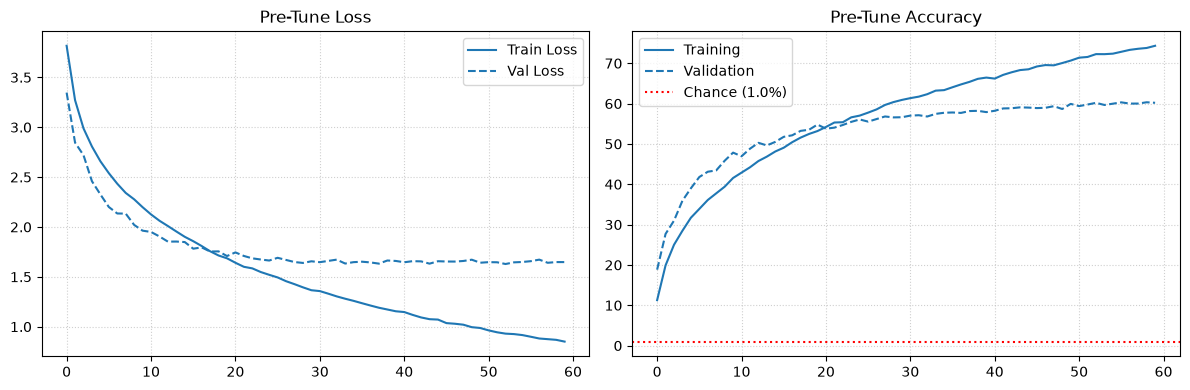


Final Pre-Tune Test Acc: 60.20% (Loss: 1.5812)
Saved pre-tuned_history.csv and pre-tuned_metrics.csv -> results/


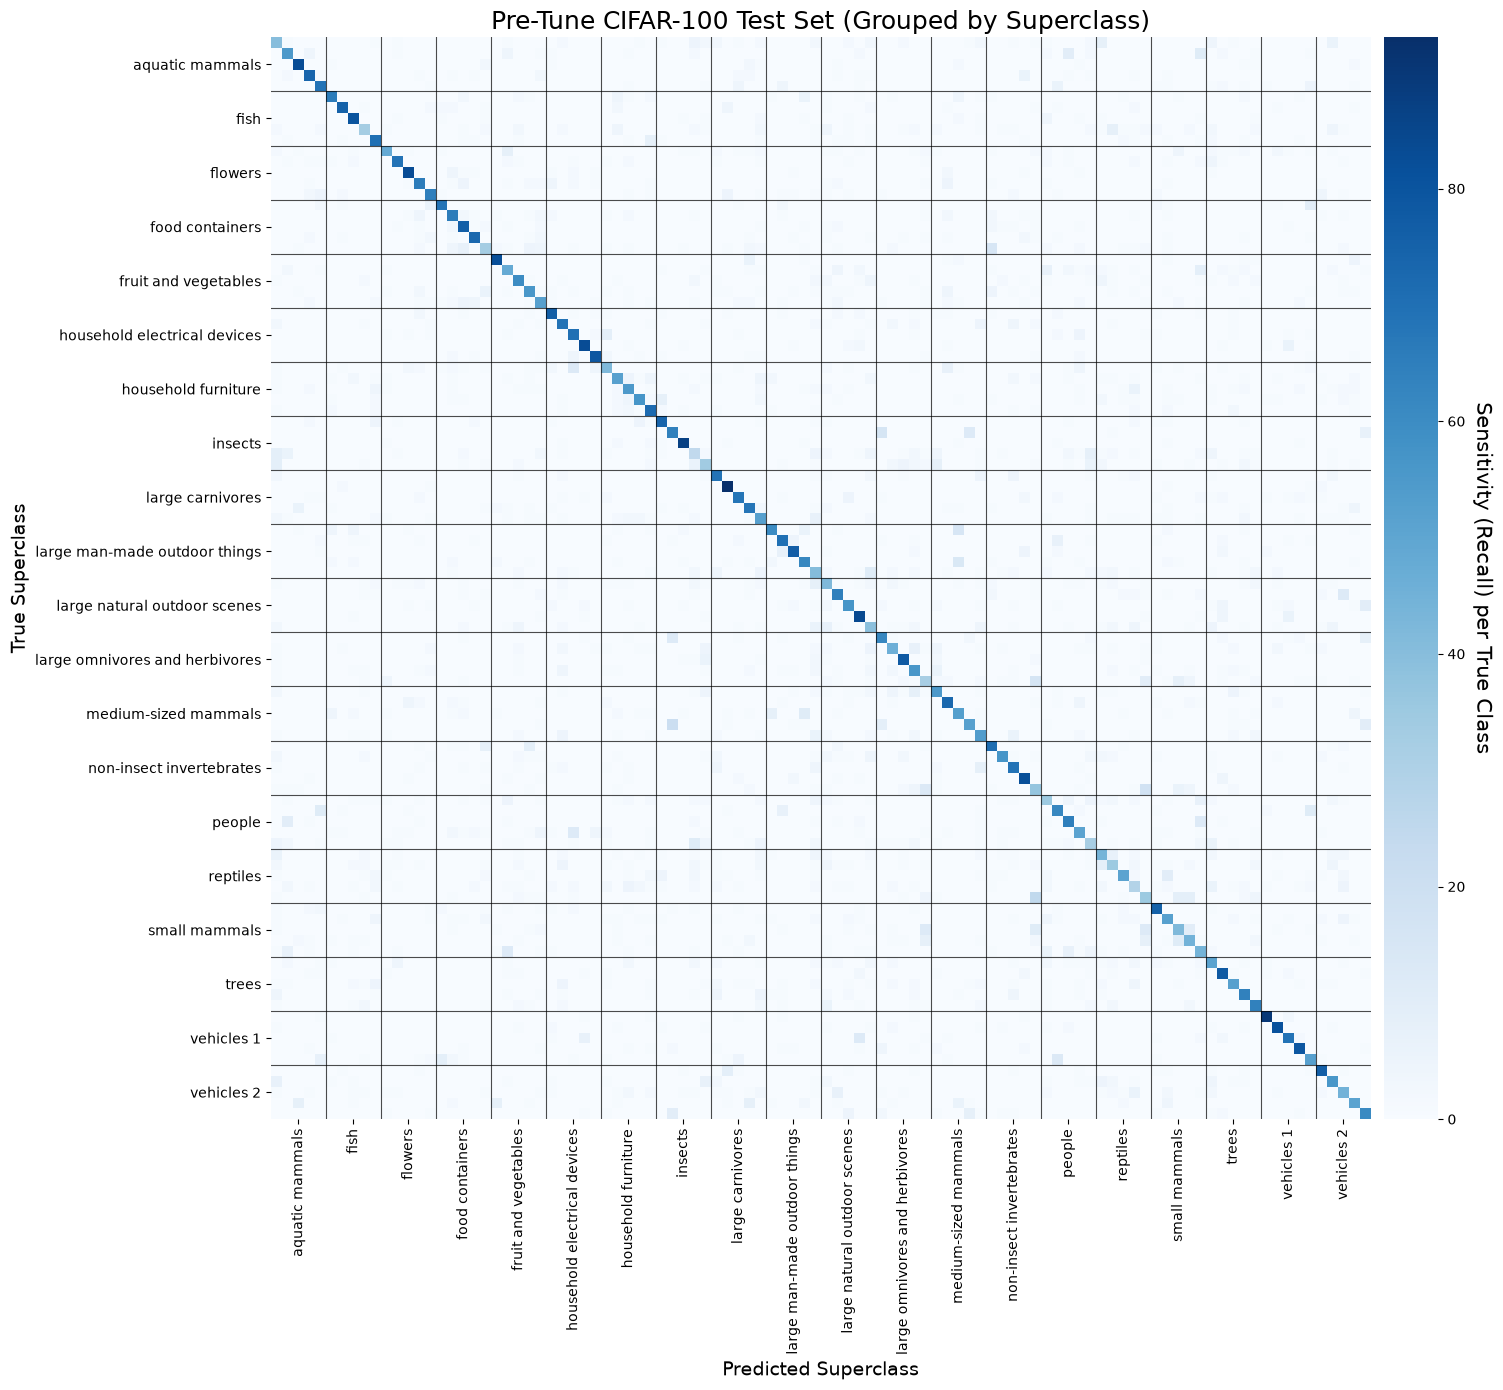


Pre-Tune Total Misclassified Samples: 3980 / 10000


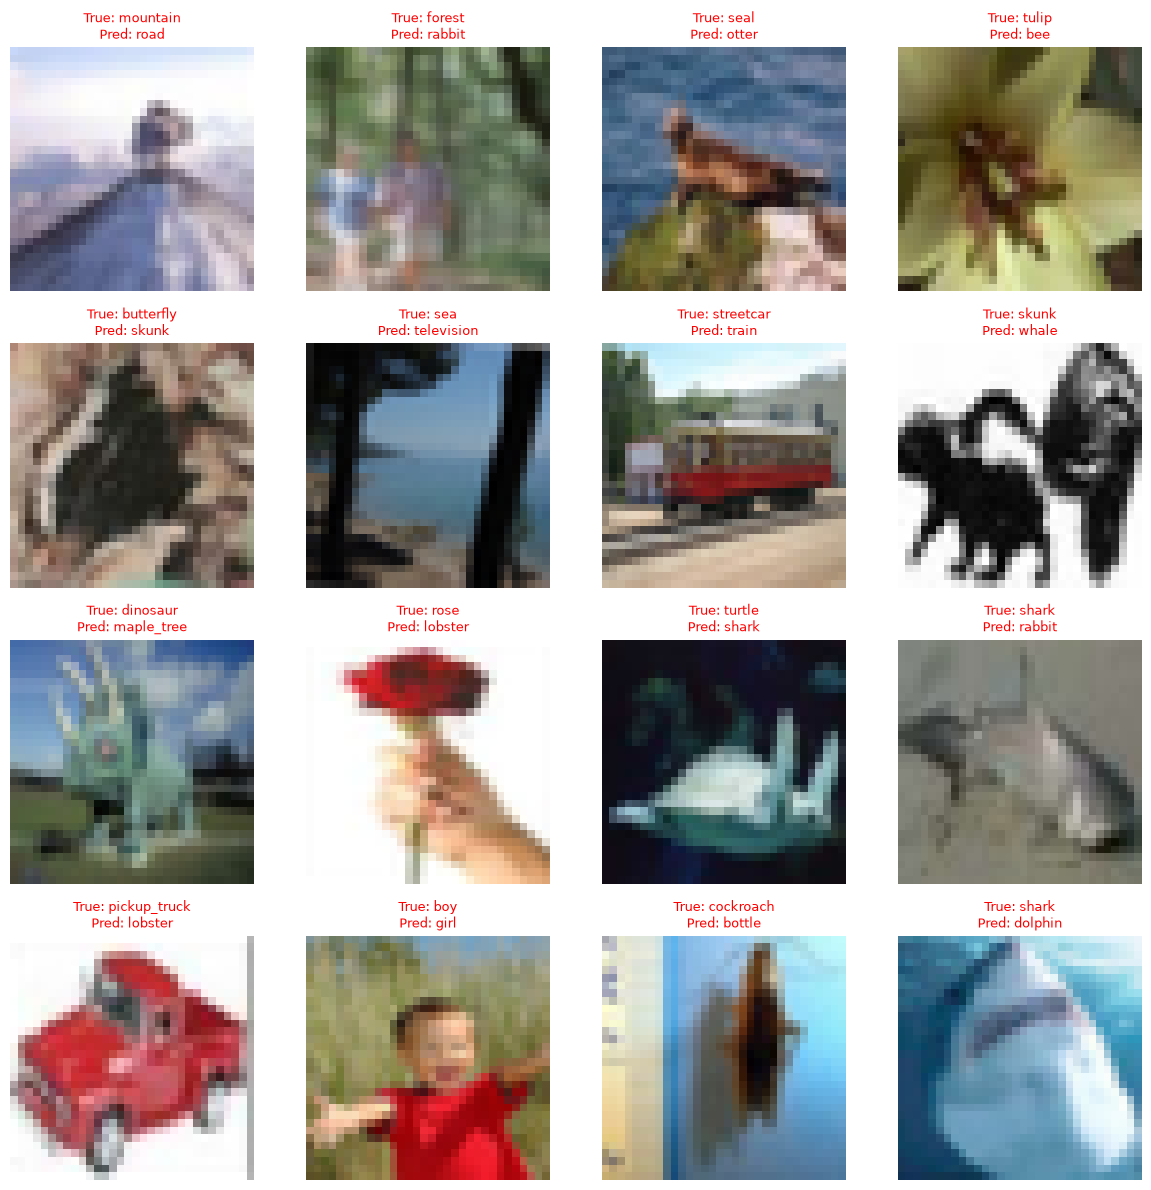

In [8]:
baseline_ckpt = os.path.join(CKPT_DIR, "cnn_baseline.pt")
baseline_model = make_cnn(BASELINE["dropout_rate"])

if os.path.exists(baseline_ckpt):
    print(f"Found checkpoint: loading {baseline_ckpt}")
    base_history, pre_train_s = load_run(baseline_ckpt, baseline_model)   # train time was stored with the checkpoint
    if pre_train_s is None:
        print("  (checkpoint has no stored train time: delete it and re-run to record one)")
else:
    print("No checkpoint found: training the pre-tune model")
    t0 = time.perf_counter()
    base_history = fit(
        baseline_model, lr=BASELINE["lr"], weight_decay=BASELINE["weight_decay"],
        batch_size=BASELINE["batch_size"], epochs=EPOCHS, patience=PATIENCE, desc="Pre-tune",
    )
    pre_train_s = time.perf_counter() - t0
    save_run(baseline_ckpt, baseline_model, base_history, pre_train_s)

plot_curves(base_history, "Pre-Tune")
pre_tune_test_loss, pre_tune_test_acc, pre_preds, pre_test_s = timed_test(baseline_model, X_test, y_test)
print(f"\nFinal Pre-Tune Test Acc: {pre_tune_test_acc:.2f}% (Loss: {pre_tune_test_loss:.4f})")
pre_results = save_model_csv("Pre-Tuned", base_history, y_test_np, pre_preds, pre_train_s, pre_test_s)
plot_diagnostics(pre_preds, y_test_np, X_test_u8.cpu(), CLASS_NAMES, title_prefix="Pre-Tune")

## Logistic-regression baseline

Logistic regression:  20%|██        | 20/100 [00:20<01:22,  1.03s/epoch, tr_loss=23.213, val_acc=7.53%, val_loss=20.640]


Early stopping at epoch 21 (best val acc 7.92%).

Final Logistic Regression Test Acc: 7.90% (Loss: 22.9031)
Saved logistic_regression_history.csv and logistic_regression_metrics.csv -> results/


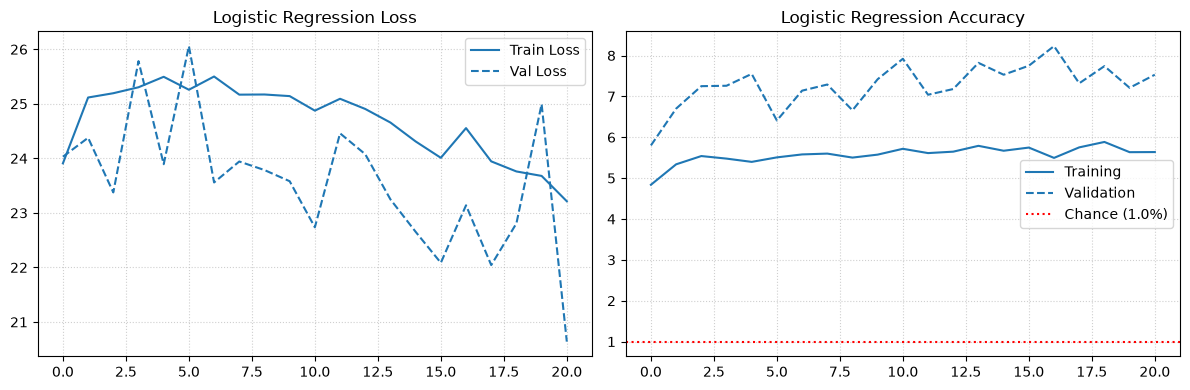

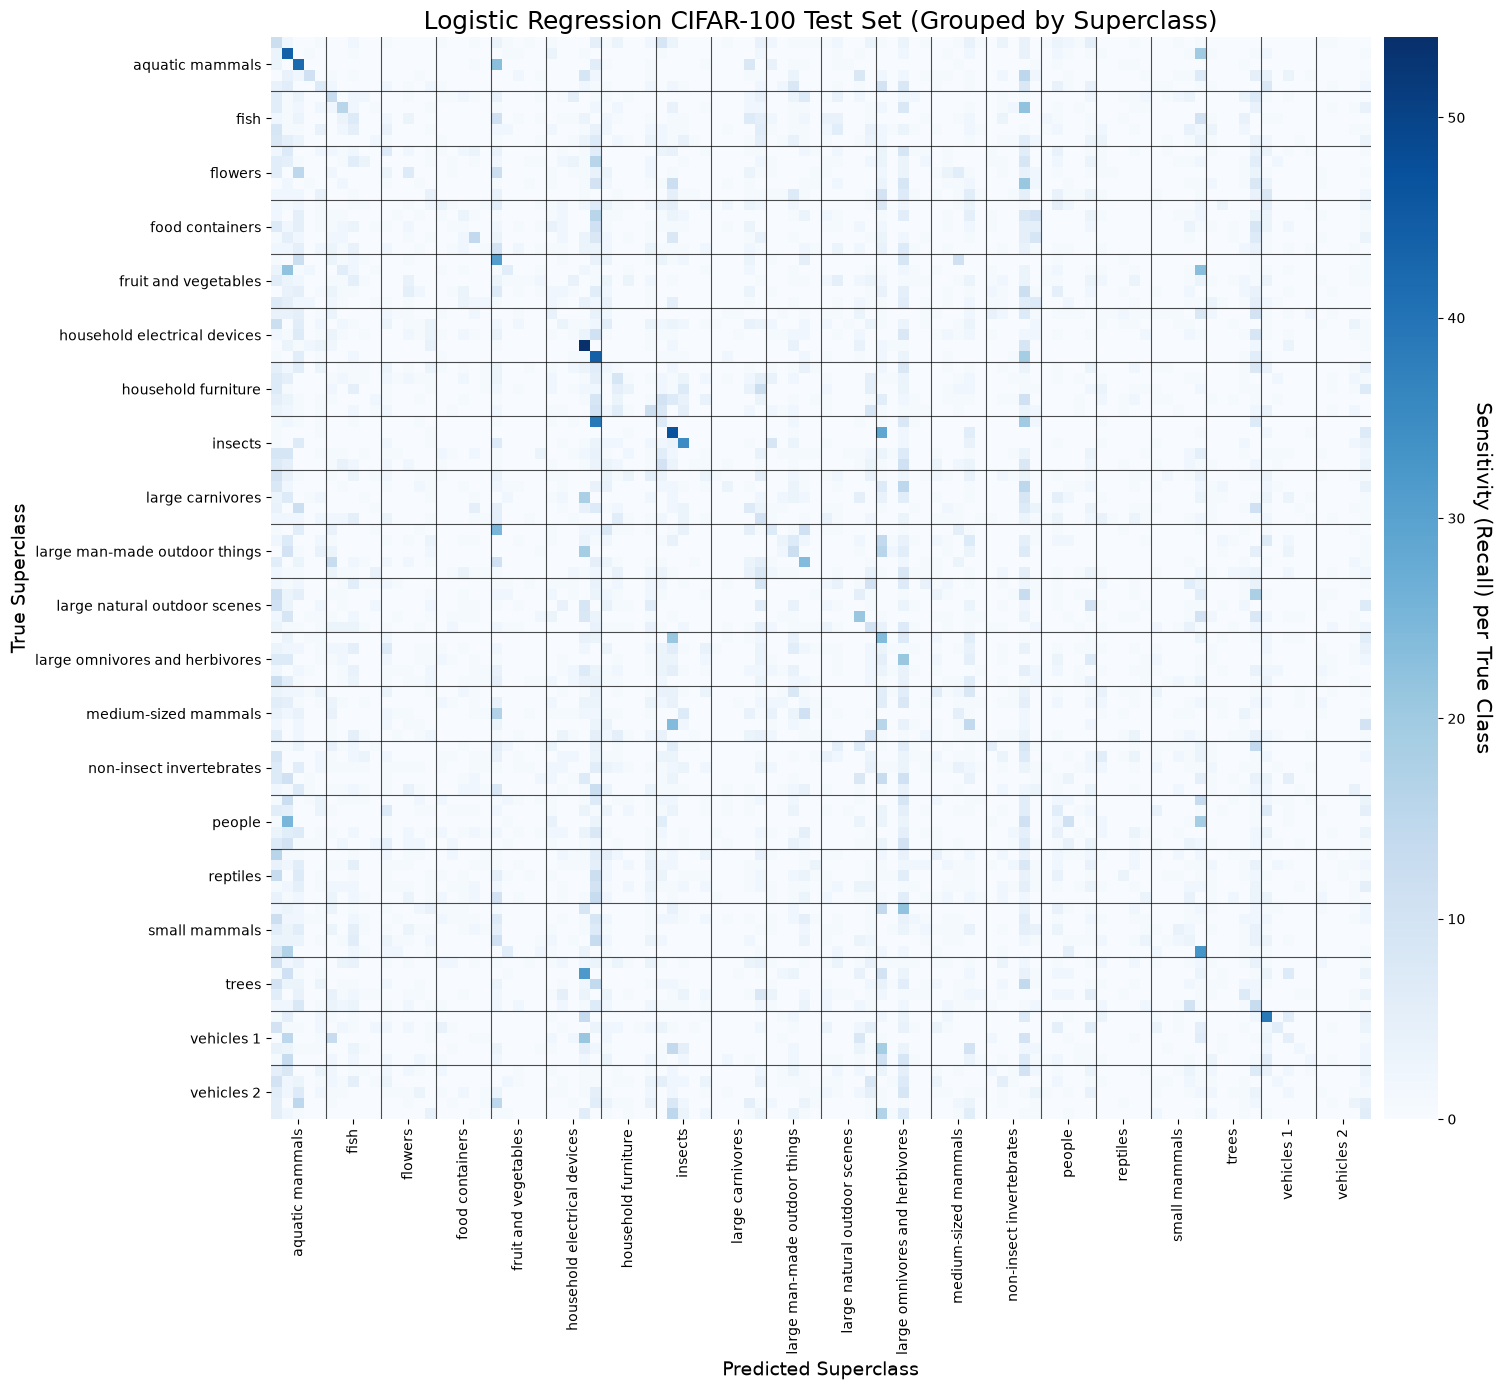


Logistic Regression Total Misclassified Samples: 9210 / 10000


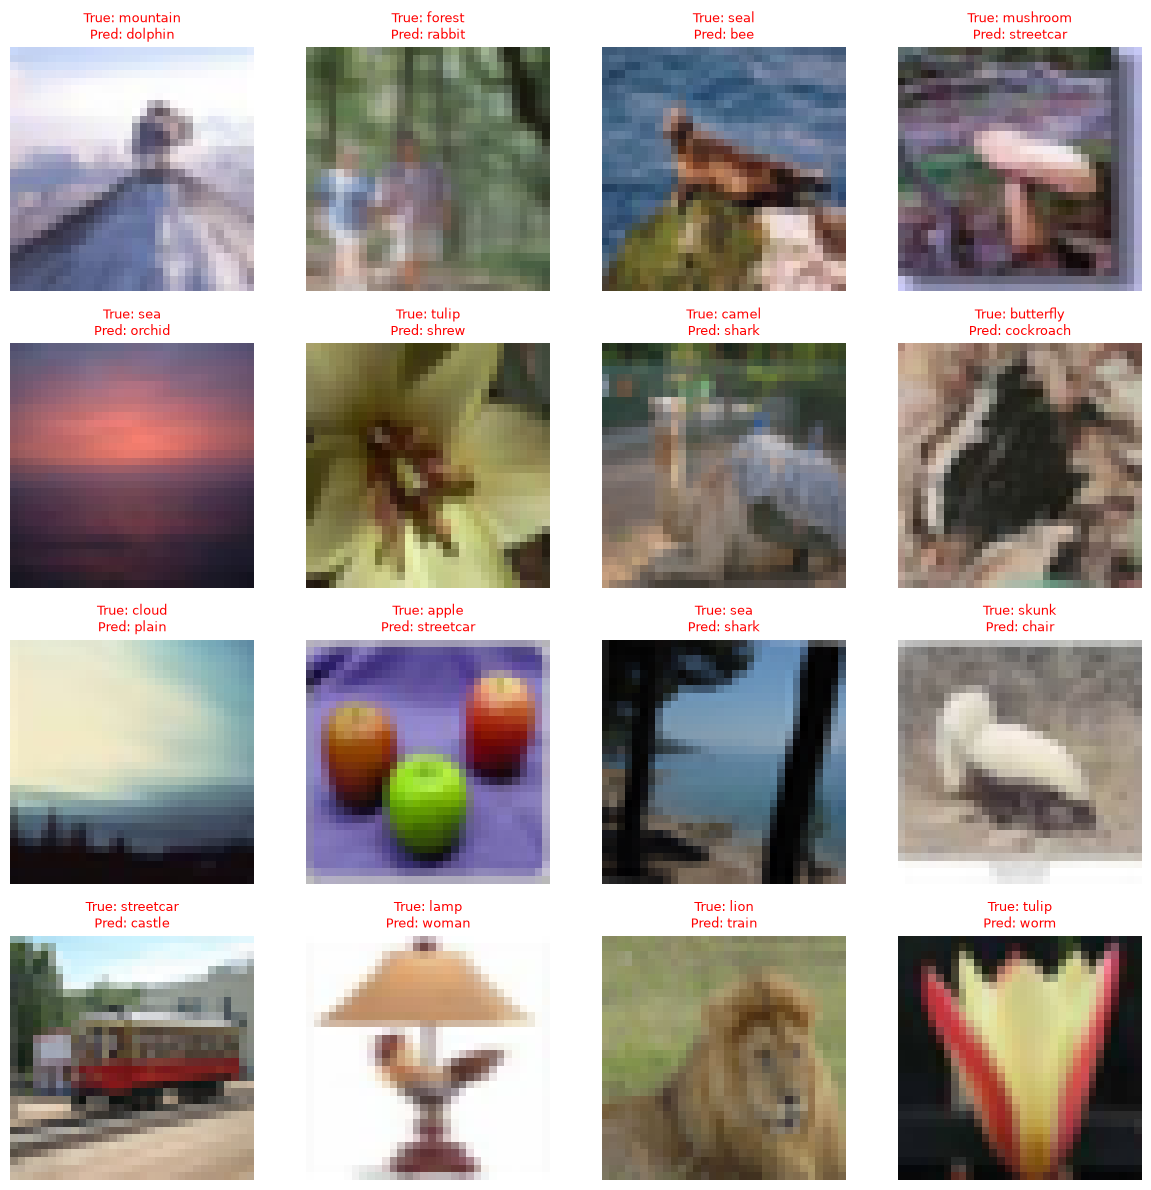

In [9]:
lr_baseline = make_logreg()
t0 = time.perf_counter()
lr_history = fit(
    lr_baseline, lr=LOGREG["lr"], weight_decay=LOGREG["weight_decay"],
    batch_size=LOGREG["batch_size"], epochs=EPOCHS, patience=PATIENCE, desc="Logistic regression",
)
lr_train_s = time.perf_counter() - t0
lr_test_loss, lr_test_acc, lr_preds, lr_test_s = timed_test(lr_baseline, X_test, y_test)
print(f"\nFinal Logistic Regression Test Acc: {lr_test_acc:.2f}% (Loss: {lr_test_loss:.4f})")
lr_results = save_model_csv("Logistic Regression", lr_history, y_test_np, lr_preds, lr_train_s, lr_test_s)

plot_curves(lr_history, "Logistic Regression")
plot_diagnostics(lr_preds, y_test_np, X_test_u8.cpu(), CLASS_NAMES, title_prefix="Logistic Regression")

## Optuna search

In [10]:
def objective(trial):
    lr = trial.suggest_float("lr", 1e-4, 1e-2, log=True)
    dropout_rate = trial.suggest_float("dropout_rate", 0.2, 0.6, step=0.1)
    weight_decay = trial.suggest_float("weight_decay", 1e-4, 1e-2, log=True)
    batch_size = trial.suggest_categorical("batch_size", BATCH_SIZES)

    model = make_cnn(dropout_rate)
    try:
        history = fit(
            model, lr=lr, weight_decay=weight_decay, batch_size=batch_size,
            epochs=N_EPOCHS, trial=trial, verbose=False,   
        )
    finally:
        del model
        if device.type == "cuda":
            torch.cuda.empty_cache()                        
    return history["val_acc"][-1]


pbar = tqdm(total=N_TRIALS, desc="Optuna Optimization Progress")


def tqdm_callback(study, trial):
    pbar.update(1)
    try:
        best = f"{study.best_value:.2f}%"  
    except ValueError:
        best = "N/A"
    pbar.set_postfix(best_acc=best)


study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED),
                            pruner=optuna.pruners.HyperbandPruner(min_resource=1, max_resource=N_EPOCHS, reduction_factor=3))

t0 = time.perf_counter()
try:
    study.optimize(objective, n_trials=N_TRIALS, callbacks=[tqdm_callback])
finally:
    pbar.close()
    optuna_s = time.perf_counter() - t0 # hyperparameter-search wall time (counts as tuned train time)
print(f"Optuna search time: {optuna_s / 60:.2f} min")

best_params = study.best_params
print(f"Best val accuracy: {study.best_value:.2f}%")
print("Best hyperparameters:")
for key, value in best_params.items():
    print(f"  {key}: {value}")

Optuna Optimization Progress: 100%|██████████| 50/50 [45:35<00:00, 54.70s/it, best_acc=55.82%]  

Optuna search time: 45.59 min
Best val accuracy: 55.82%
Best hyperparameters:
  lr: 0.0012399967836846098
  dropout_rate: 0.2
  weight_decay: 0.00869299151113955
  batch_size: 64


## Final tuned model (same pipeline as the Pre-Tuned CNN)

Tuned:  85%|████████▌ | 85/100 [08:42<01:32,  6.15s/epoch, tr_loss=0.410, val_acc=60.86%, val_loss=1.886]


Early stopping at epoch 86 (best val acc 60.91%).
Tuned train time: 54.30 min (Optuna 45.59 + final fit 8.71)
Saved tuned_history.csv and tuned_metrics.csv -> results/


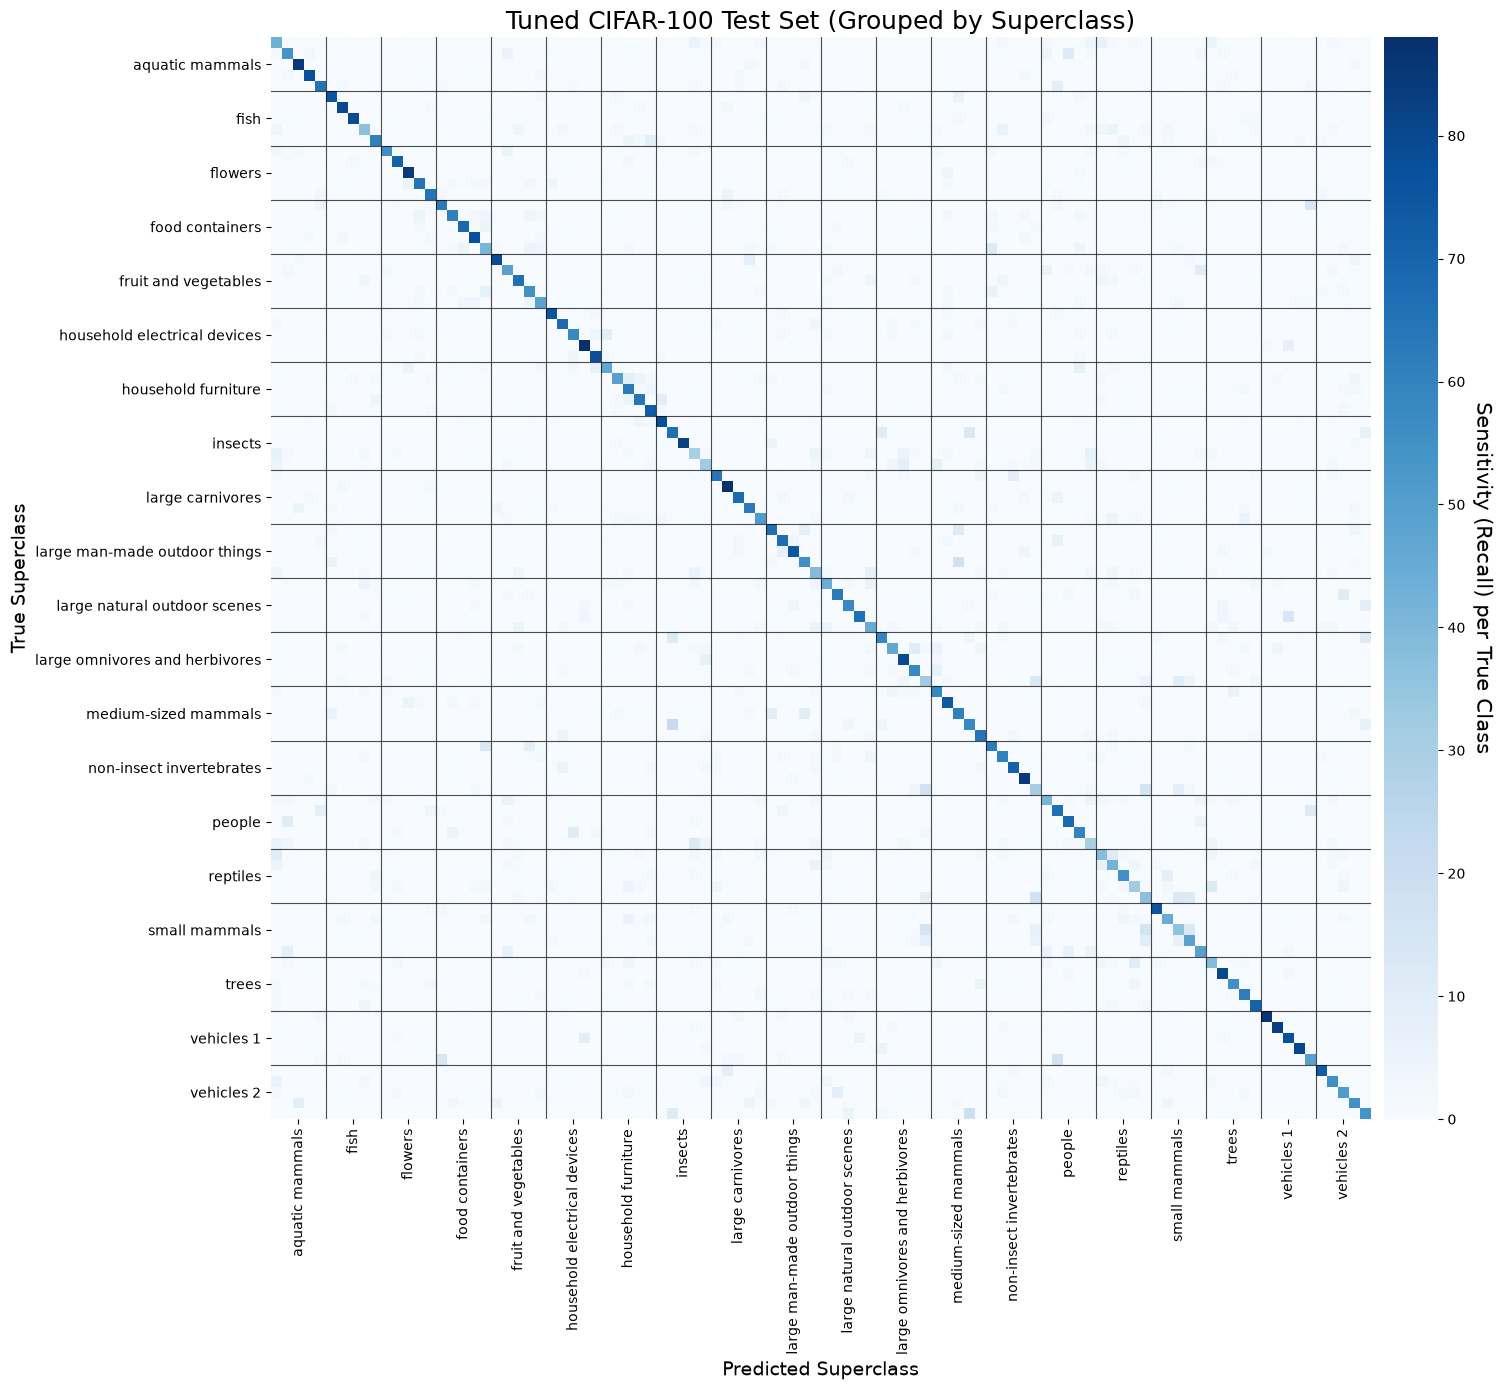


Tuned Total Misclassified Samples: 3934 / 10000


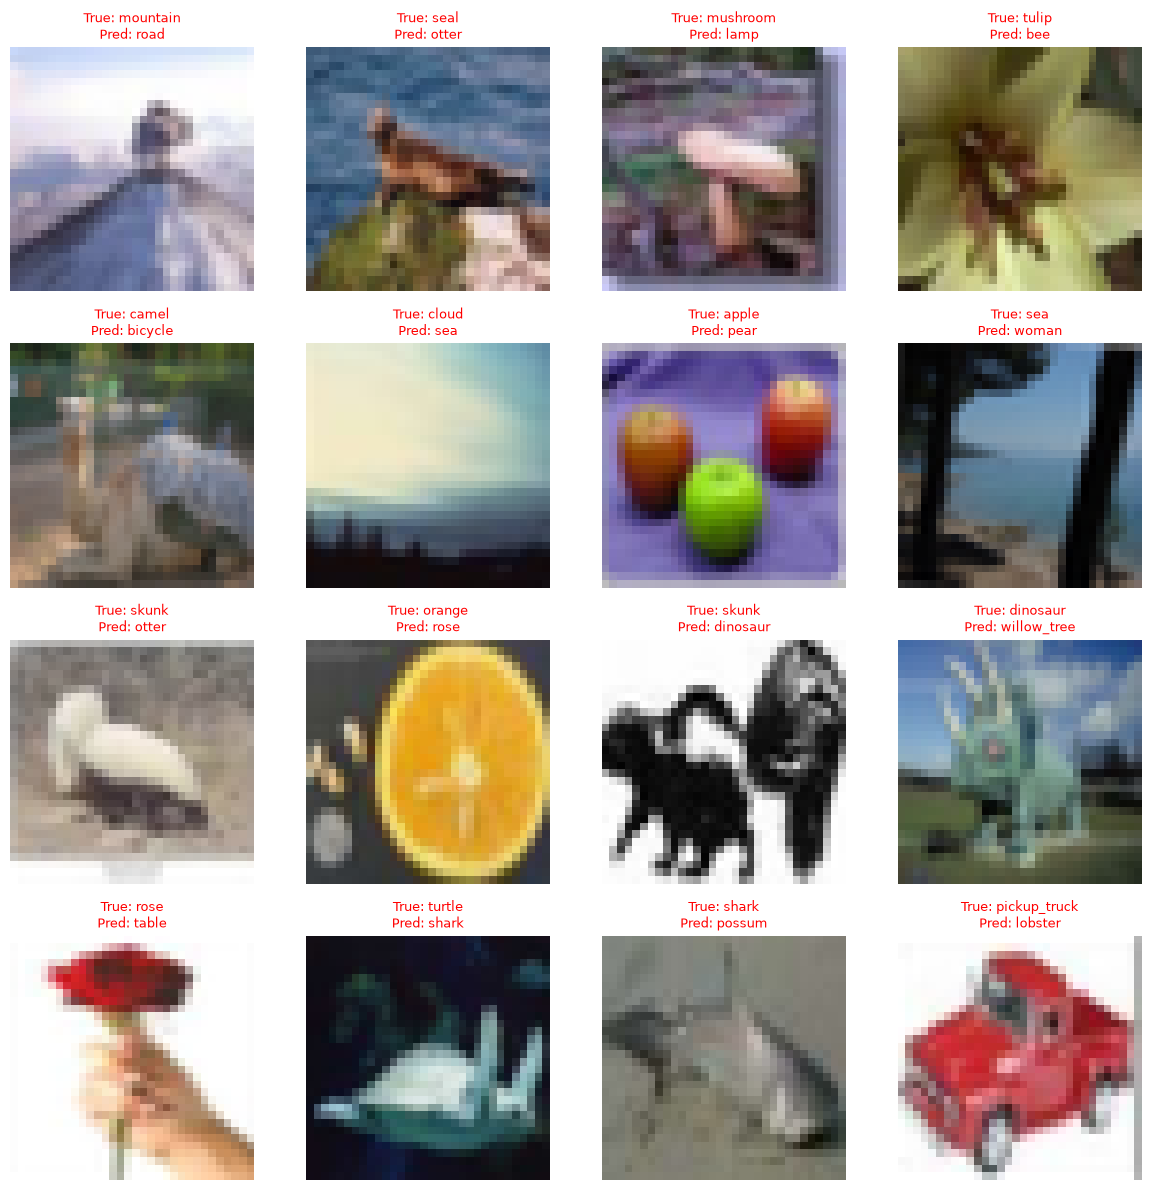

In [11]:
tuned_ckpt = os.path.join(CKPT_DIR, "tuned.pt")
tuned_model = make_cnn(best_params["dropout_rate"])
t0 = time.perf_counter()
tuned_history = fit(
    tuned_model, lr=best_params["lr"], weight_decay=best_params["weight_decay"],
    batch_size=best_params["batch_size"], epochs=EPOCHS, patience=PATIENCE, desc="Tuned",
)
final_fit_s = time.perf_counter() - t0
tuned_train_s = optuna_s + final_fit_s           # train time = Optuna search + final training run
save_run(tuned_ckpt, tuned_model, tuned_history, tuned_train_s)
print(f"Tuned train time: {tuned_train_s / 60:.2f} min (Optuna {optuna_s / 60:.2f} + final fit {final_fit_s / 60:.2f})")

test_loss, test_acc, tuned_preds, tuned_test_s = timed_test(tuned_model, X_test, y_test)
tuned_results = save_model_csv("Tuned", tuned_history, y_test_np, tuned_preds, tuned_train_s, tuned_test_s)
plot_diagnostics(tuned_preds, y_test_np, X_test_u8.cpu(), CLASS_NAMES, title_prefix="Tuned")

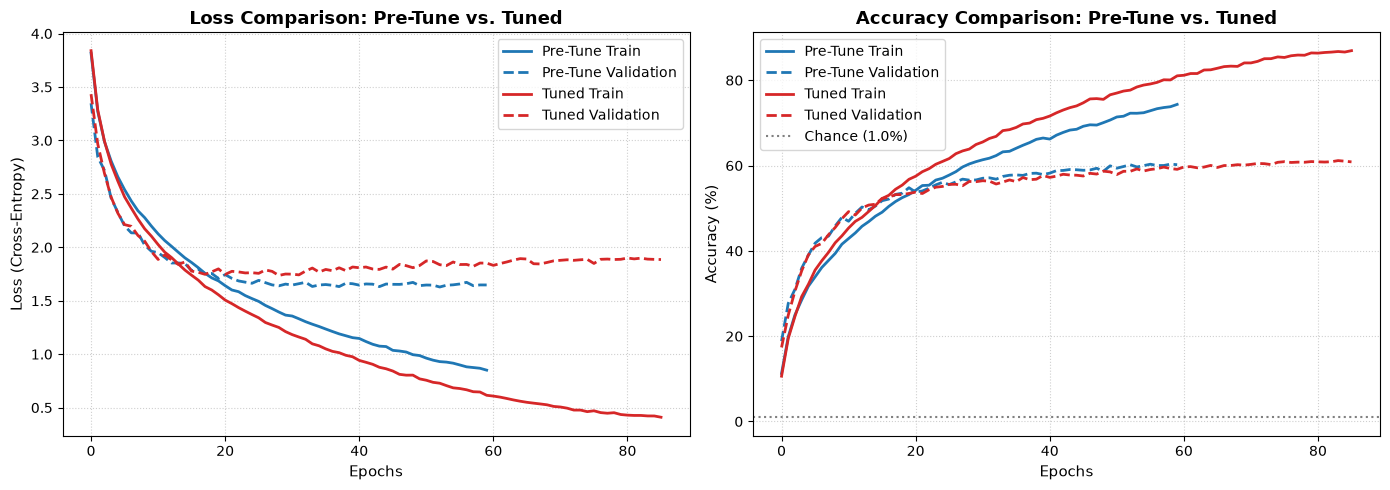


--- Model Performance Comparison ---
Chance accuracy:        1.00%
Logistic regression:    7.90% (Loss: 22.9031)
Before tuning (CNN):    60.20% (Loss: 1.5812)
After tuning (CNN):     60.66% (Loss: 1.8176)
Accuracy difference:    +0.46%


In [17]:
plot_comparison_curves(base_history, tuned_history)

print("\n--- Model Performance Comparison ---")
print(f"Chance accuracy:        {DUMMY_ACC:.2f}%")
print(f"Logistic regression:    {lr_test_acc:.2f}% (Loss: {lr_test_loss:.4f})")
print(f"Before tuning (CNN):    {pre_tune_test_acc:.2f}% (Loss: {pre_tune_test_loss:.4f})")
print(f"After tuning (CNN):     {test_acc:.2f}% (Loss: {test_loss:.4f})")
print(f"Accuracy difference:    {test_acc - pre_tune_test_acc:+.2f}%")

## Final comparison: metrics and time

,accuracy,precision,recall,f1,train_time_min,test_time_min
model,,,,,,
Pre-Tuned,60.20,60.47,60.20,60.06,6.20,0.0
Tuned,60.66,60.64,60.66,60.51,54.30,0.0
Logistic Regression,7.90,7.00,7.90,5.97,0.34,0.0


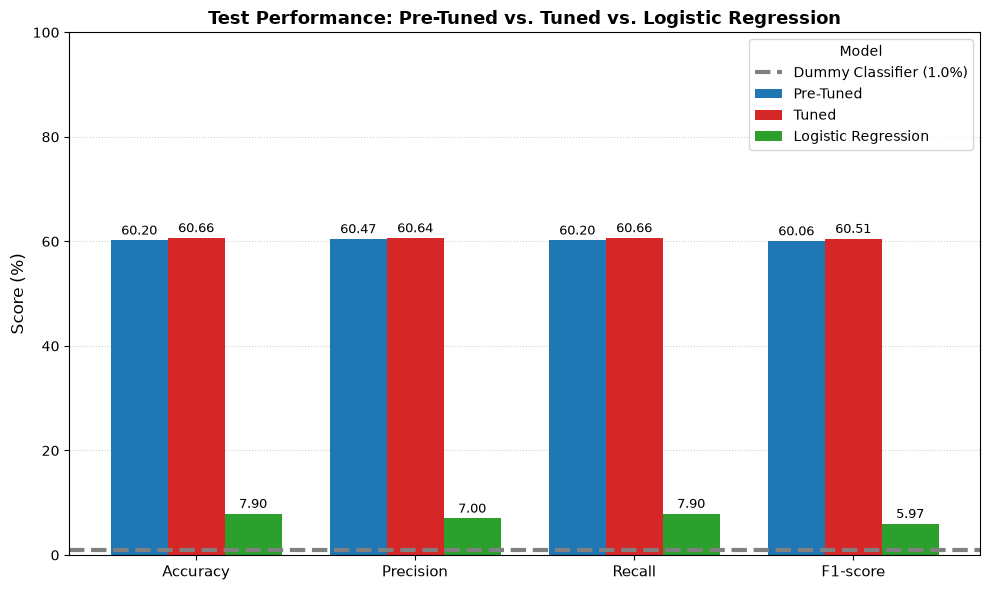

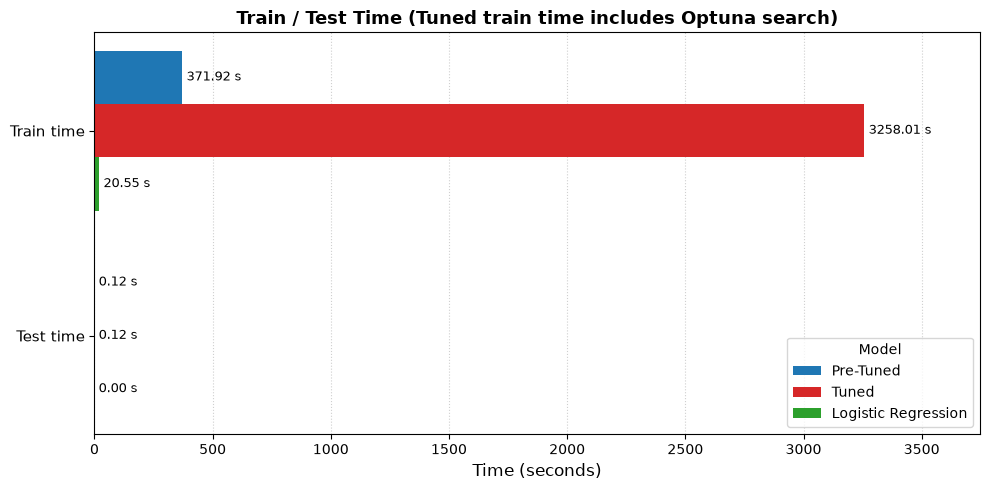

In [23]:
all_results = [pre_results, tuned_results, lr_results]
pd.DataFrame(all_results).to_csv(os.path.join(RESULTS_DIR, "all_models_summary.csv"), index=False)
display(pd.DataFrame(all_results).set_index("model").round(2))

plot_metric_comparison(all_results)
plot_time_comparison(all_results)